# 🍄 Mushroom Classification – zero kills, as little waste as possible

**Goal:** a model that never labels a **poisonous mushroom as edible** while throwing away as few edible mushrooms as possible.

| Term | Meaning in this notebook |
|---|---|
| Positive class (`1`) | poisonous |
| **False negative (FN) = "kill" / "death"** | a poisonous mushroom is labelled edible – the worst possible error |
| **False positive (FP) = "edible but uneaten"** | an edible mushroom is labelled poisonous and thrown away |
| Recall | share of poisonous mushrooms that were caught (1.0 means zero kills) |
| Threshold | poison probability above which the model says "poisonous" |

**Leaderboard ranking:** fewest deaths first, then fewest "edible but uneaten".

**Contents**
1. Imports
2. Load data
3. Explore data (including "which features point to poisonous?" and the limit of the data)
4. Split data
5. Pipeline and baseline
6. Experiments: models, preprocessing, hyperparameters
7. ROC curve and threshold
8. Cost function and threshold with nested CV
9. Caution versus yield: the finalists
10. Check on held-out data
11. Which features does the model use?
12. Create submission files
13. First upload and second round
14. Upload log
15. Summary

## 1. Imports

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, GridSearchCV,
    cross_val_predict, cross_validate, TunedThresholdClassifierCV,
)
from sklearn.metrics import (
    confusion_matrix, make_scorer, roc_curve, roc_auc_score,
    RocCurveDisplay, ConfusionMatrixDisplay,
)

sns.set_style("whitegrid")
pd.set_option("display.width", 200)

## 2. Load data

The data lives in the `data/` folder next to this notebook. Submission files are written to `submissions/`.

**Error handling:** if a file is missing, the cell stops immediately with a clear message. Otherwise the error would only show up later and be harder to understand.

In [2]:
DATA_DIR = "data"
OUTPUT_DIR = "submissions"

# Check that all three files exist
for file_name in ["train.csv", "test.csv", "sample_submission.csv"]:
    path = os.path.join(DATA_DIR, file_name)
    if not os.path.exists(path):
        raise FileNotFoundError(
            f"'{file_name}' was not found in '{DATA_DIR}'. "
            "Please check the folder or adjust DATA_DIR."
        )

# Create the output folder if it does not exist yet
os.makedirs(OUTPUT_DIR, exist_ok=True)
print("Reading data from:", DATA_DIR, "| writing submissions to:", OUTPUT_DIR)

Reading data from: data | writing submissions to: submissions


In [3]:
# Training data: features + known outcome. The Id is only a name, not a feature -> use it as the index.
mush_data = pd.read_csv(os.path.join(DATA_DIR, "train.csv")).set_index("Id")

def prepare_features(df):
    # Brings the features into one consistent form (same for training and competition data).
    df = df.copy()
    # 'bruises' is True/False. We turn it into the codes 't'/'f' from the data description,
    # so that every column is treated the same way (all categories).
    df["bruises"] = df["bruises"].map({True: "t", False: "f"})
    return df

X = prepare_features(mush_data.drop(columns="poisonous"))
y = mush_data["poisonous"]

# Competition data: same features, but no outcome. Put the columns into the same order.
X_comp = pd.read_csv(os.path.join(DATA_DIR, "test.csv")).set_index("Id")
X_comp = prepare_features(X_comp)[X.columns]

# Sample file: defines the format of a submission
sample_submission = pd.read_csv(os.path.join(DATA_DIR, "sample_submission.csv"))

features = list(X.columns)
print("Training:", X.shape, "| Competition:", X_comp.shape)
X.head()

Training: (6499, 6) | Competition: (1625, 6)


,cap.shape,cap.color,bruises,stalk.color.above.ring,stalk.color.below.ring,population
Id,,,,,,
6573,k,e,f,w,w,v
4426,f,e,t,p,w,y
7018,b,w,f,w,w,s
5789,k,g,f,w,w,n
6187,f,n,t,p,g,v


## 3. Explore data

### 3.1 Overview

In [4]:
print("Data types:")
print(X.dtypes.to_string())

print("\nMissing values (training / competition):", X.isna().sum().sum(), "/", X_comp.isna().sum().sum())

print("\nTarget distribution (0 = edible, 1 = poisonous):")
print(y.value_counts().rename({0: "edible", 1: "poisonous"}).to_string())
print("Share poisonous:", round(y.mean(), 3))

# Does the competition contain categories the training data has never seen?
for feature in features:
    new_categories = set(X_comp[feature]) - set(X[feature])
    if new_categories:
        print(f"Warning: '{feature}' has unknown categories in the competition data: {new_categories}")
print("\nUnknown categories in the competition data: checked.")

Data types:
cap.shape                 object
cap.color                 object
bruises                   object
stalk.color.above.ring    object
stalk.color.below.ring    object
population                object

Missing values (training / competition): 0 / 0

Target distribution (0 = edible, 1 = poisonous):
poisonous
edible       3342
poisonous    3157
Share poisonous: 0.486

Unknown categories in the competition data: checked.


**Observations**
- All 6 features are **categories** (letter codes). A model needs numbers, so we have to convert them (section 5).
- There are **no missing values**. We still include an imputer so the model can cope with incomplete new data.
- The classes are almost **balanced** (about 49 % poisonous). Accuracy is therefore not misleading because of imbalance, but because the two kinds of error are **not equally bad**.

### 3.2 Which features point to "poisonous"?

For every category we compute the **poison rate**: what share of the mushrooms with this property were poisonous?
The dashed line is the average over all mushrooms. `n` is the number of mushrooms – with a small `n` the rate is unreliable.

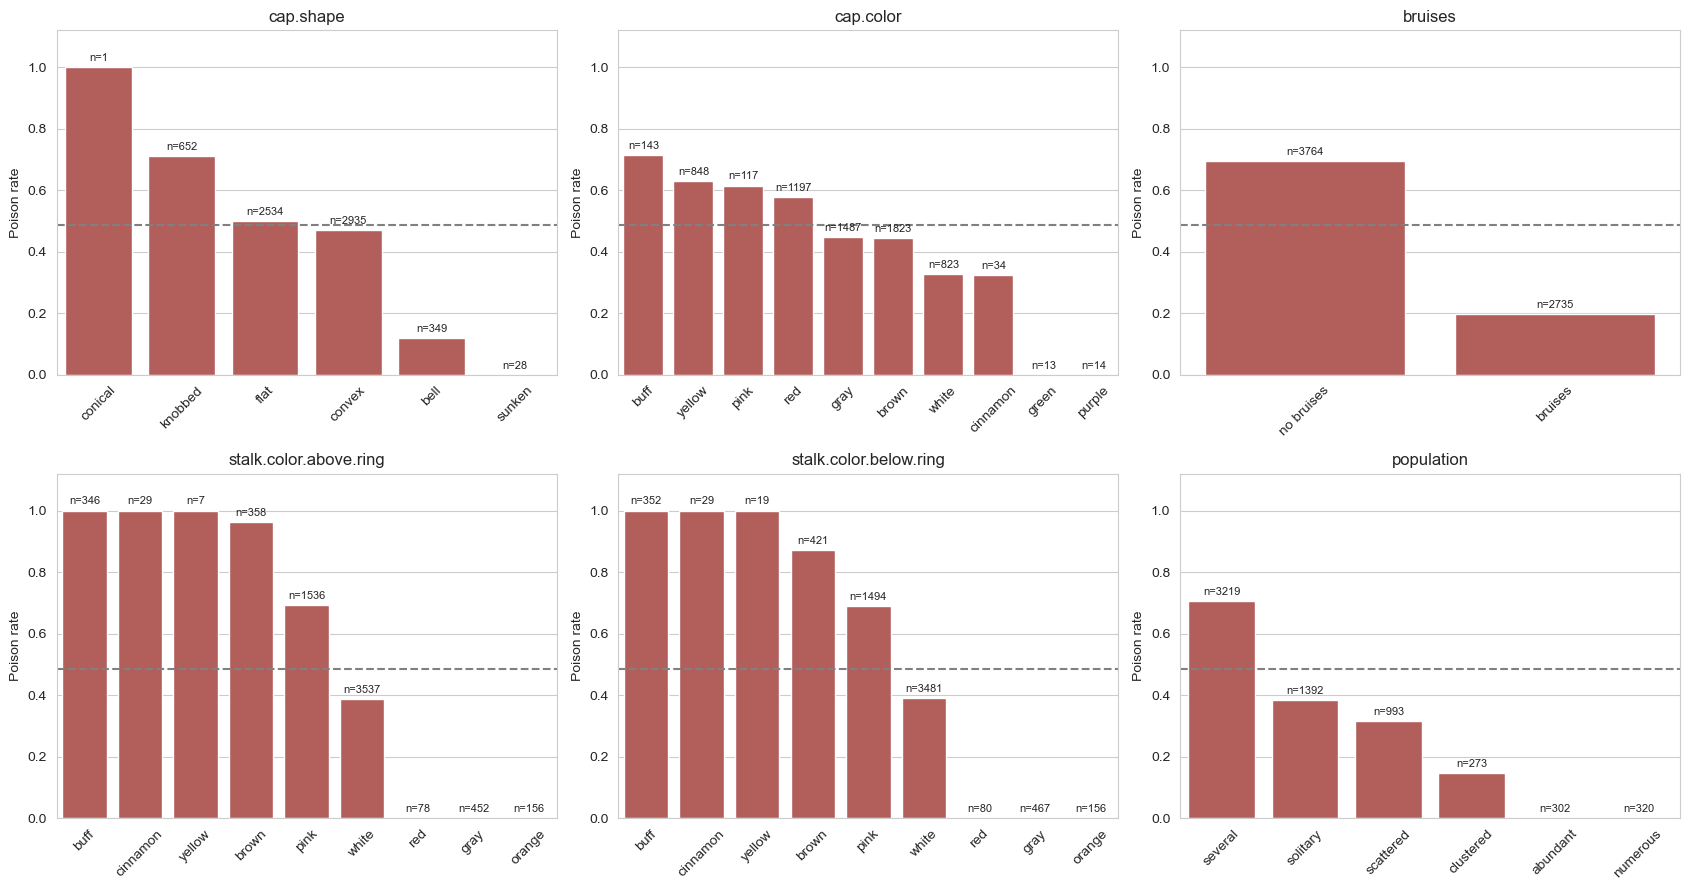

In [5]:
# Plain-text names of the codes (from the data description)
stalk_colors = {"n": "brown", "b": "buff", "c": "cinnamon", "g": "gray", "o": "orange",
                "p": "pink", "e": "red", "w": "white", "y": "yellow"}
CATEGORY_NAMES = {
    "cap.shape": {"b": "bell", "c": "conical", "x": "convex", "f": "flat", "k": "knobbed", "s": "sunken"},
    "cap.color": {"n": "brown", "b": "buff", "c": "cinnamon", "g": "gray", "r": "green",
                  "p": "pink", "u": "purple", "e": "red", "w": "white", "y": "yellow"},
    "bruises": {"t": "bruises", "f": "no bruises"},
    "stalk.color.above.ring": stalk_colors,
    "stalk.color.below.ring": stalk_colors,
    "population": {"a": "abundant", "c": "clustered", "n": "numerous",
                   "s": "scattered", "v": "several", "y": "solitary"},
}

data = X.assign(poisonous=y)

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
all_tables = []
for ax, feature in zip(axes.ravel(), features):
    tab = (data.groupby(feature)["poisonous"]
           .agg(n="size", poison_rate="mean")
           .sort_values("poison_rate", ascending=False)
           .reset_index())
    tab["name"] = tab[feature].map(CATEGORY_NAMES[feature])
    all_tables.append(tab.assign(feature=feature)[["feature", "name", "n", "poison_rate"]])

    sns.barplot(data=tab, x="name", y="poison_rate", color="#c0504d", ax=ax)
    ax.axhline(y.mean(), color="grey", linestyle="--")
    for i, row in tab.iterrows():
        ax.text(i, row["poison_rate"] + 0.02, f"n={row['n']}", ha="center", fontsize=8)
    ax.set_title(feature)
    ax.set_xlabel("")
    ax.set_ylabel("Poison rate")
    ax.set_ylim(0, 1.12)
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

In [6]:
# The clearest signals as a table (only categories with at least 30 mushrooms)
signals = pd.concat(all_tables)
signals = signals[signals["n"] >= 30]

print("Strongest warning signs (highest poison rate):")
print(signals.sort_values("poison_rate", ascending=False).head(8).round(3).to_string(index=False))

print("\nNever or almost never poisonous (lowest poison rate):")
print(signals.sort_values("poison_rate").head(8).round(3).to_string(index=False))

Strongest warning signs (highest poison rate):
               feature       name    n  poison_rate
stalk.color.below.ring       buff  352        1.000
stalk.color.above.ring       buff  346        1.000
stalk.color.above.ring      brown  358        0.964
stalk.color.below.ring      brown  421        0.872
             cap.color       buff  143        0.713
             cap.shape    knobbed  652        0.712
            population    several 3219        0.705
               bruises no bruises 3764        0.696

Never or almost never poisonous (lowest poison rate):
               feature     name   n  poison_rate
            population numerous 320          0.0
stalk.color.below.ring      red  80          0.0
stalk.color.below.ring     gray 467          0.0
stalk.color.above.ring   orange 156          0.0
stalk.color.above.ring     gray 452          0.0
stalk.color.above.ring      red  78          0.0
            population abundant 302          0.0
stalk.color.below.ring   orange 156   

**What this tells a health ministry**
- **Stalk colour** is the strongest feature: `buff`, `cinnamon` and `brown` stalks were almost always poisonous; `gray`, `orange` and `red` never.
- **No bruises:** about 70 % poisonous. With bruises: about 20 %.
- **Population:** `several` is about 70 % poisonous; `abundant` and `numerous` were never poisonous.
- **Cap shape and cap colour** are weaker: the large groups (convex, flat, brown, gray) sit close to the average. Exceptions are `knobbed` (71 % poisonous) and `bell` (12 %).

Important: a single feature is never enough to call a mushroom edible. White stalks, for example, are sometimes poisonous and sometimes not. Only the **combination** of features decides – and even that is not always enough, as the next section shows.

### 3.3 The limit of the data: mushrooms that look identical

With 6 features there are only a few distinct **feature combinations**. To the model, many mushrooms look exactly the same.
We count how many combinations are **pure edible**, **pure poisonous** or **mixed**.

In [7]:
# Each row of 'combos' is one feature combination with its record in the training data
combos = (data.groupby(features)["poisonous"]
          .agg(count="size", poisonous="sum")
          .reset_index())
combos["edible"] = combos["count"] - combos["poisonous"]
combos["type"] = "mixed"
combos.loc[combos["poisonous"] == 0, "type"] = "pure edible"
combos.loc[combos["edible"] == 0, "type"] = "pure poisonous"

print("Distinct combinations in training:", len(combos), "for", len(X), "mushrooms\n")
print(combos.groupby("type").agg(combinations=("count", "size"), mushrooms=("count", "sum"),
                                 poisonous=("poisonous", "sum"), edible=("edible", "sum")).to_string())

Distinct combinations in training: 378 for 6499 mushrooms

                combinations  mushrooms  poisonous  edible
type                                                      
mixed                     18        897        529     368
pure edible              226       2974          0    2974
pure poisonous           134       2628       2628       0


In [8]:
# Where do the competition mushrooms fall?
comp_combos = X_comp.reset_index().merge(combos, on=features, how="left")
comp_combos["type"] = comp_combos["type"].fillna("unknown (never seen in training)")
print("Competition mushrooms by type of their combination:")
print(comp_combos["type"].value_counts().to_string())

# In mixed combinations no model can tell poisonous from edible.
# Whoever wants zero kills has to say 'poisonous' there every time.
# Expected number of edible mushrooms thrown away as a result:
mixed = comp_combos[comp_combos["type"] == "mixed"]
expected = (mixed["edible"] / mixed["count"]).sum()
print(f"\nExpected 'edible but uneaten' from mixed combinations alone: {expected:.0f}")

Competition mushrooms by type of their combination:
type
pure edible                         780
pure poisonous                      638
mixed                               201
unknown (never seen in training)      6

Expected 'edible but uneaten' from mixed combinations alone: 81


**The key insight from the data analysis**

- In the **mixed** combinations, poisonous and edible mushrooms look identical. No model can separate them.
- For zero kills you have to say "poisonous" there every time. In the competition that costs roughly **80 edible mushrooms** – regardless of the model.
- That is why everyone on the leaderboard clusters at zero kills and 80–95 "uneaten". It is not a weakness of the models but the **information limit of the 6 visible features**.
- There is only room to manoeuvre with rare and never-seen combinations. There, what matters is how **cautious** the model is.

## 4. Split data

We set aside 20 % of the training data as a **hold-out set**. It is only used once, at the very end (section 10).
All experiments run with **cross-validation** on the remaining 80 %.

`stratify=y` makes sure both parts have the same share of poisonous mushrooms.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("For experiments:", X_train.shape, "| Hold-out set:", X_test.shape)

# One fixed splitter for all comparisons: 10 folds, shuffled, same poison share in every fold.
# This way all models are compared on exactly the same splits.
splitter = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

# Conversion factor: scale CV errors to the size of the competition set (1625 mushrooms)
SCALE = len(X_comp) / len(X_train)

For experiments: (5199, 6) | Hold-out set: (1300, 6)


## 5. Pipeline and baseline

The pipeline does three things in sequence:
1. **Imputer:** fills missing values with the most frequent category.
2. **Encoder:** converts categories into numbers. The default is **one-hot encoding**: every category gets its own 0/1 column. That fits because colours and shapes have no order.
3. **Model.**

We do not need a scaler: after one-hot encoding all values are already 0 or 1.

In [10]:
def build_pipeline(classifier, encoder="onehot"):
    # Builds the full pipeline: imputer -> encoder -> model
    if encoder == "onehot":
        # handle_unknown='ignore': a category never seen before does not crash the model,
        # it simply gets a 0 in every column
        enc = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    elif encoder == "ordinal":
        # Ordinal: every category gets a number (a=0, b=1, ...). Unknown values become -1.
        enc = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
    else:
        raise ValueError(f"Unknown encoder: {encoder}")
    return make_pipeline(SimpleImputer(strategy="most_frequent"), enc, classifier)


def evaluate(y_true, y_pred):
    # Counts both kinds of error and computes recall and accuracy.
    # labels=[0, 1] makes sure the matrix is always 2x2, even if one class is missing.
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        "Kills (FN)": int(fn),
        "Uneaten (FP)": int(fp),
        "Recall": float(round(tp / (tp + fn), 4)),
        "Accuracy": float(round((tp + tn) / len(y_true), 4)),
    }

### Baseline: decision tree with the default threshold 0.5

`cross_val_predict` returns one prediction per mushroom from a model that has **not** seen that mushroom.

Baseline (cross-validation): {'Kills (FN)': 91, 'Uneaten (FP)': 122, 'Recall': 0.964, 'Accuracy': 0.959}
Scaled to 1625 competition mushrooms: about 28 kills, 38 uneaten


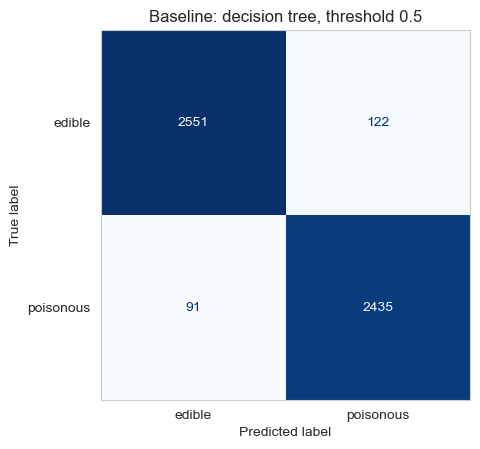

In [11]:
baseline = build_pipeline(DecisionTreeClassifier(random_state=42))
cv_preds = cross_val_predict(baseline, X_train, y_train, cv=splitter)

result = evaluate(y_train, cv_preds)
print("Baseline (cross-validation):", result)
print(f"Scaled to 1625 competition mushrooms: about {result['Kills (FN)'] * SCALE:.0f} kills, "
      f"{result['Uneaten (FP)'] * SCALE:.0f} uneaten")

ConfusionMatrixDisplay.from_predictions(
    y_train, cv_preds, display_labels=["edible", "poisonous"], cmap="Blues", colorbar=False
)
plt.title("Baseline: decision tree, threshold 0.5")
plt.grid(False)
plt.show()

**Problem:** the accuracy looks good, but the bottom-left cell holds the **kills**. With the default threshold 0.5 the tree says "edible" as soon as the majority of identical-looking mushrooms was edible. In the mixed combinations that is deadly.

The solution is not a different model but a different **threshold** (sections 7 and 8). First, though, we find out which model gives the best foundation.

## 6. Experiments

### 6.1 Different models

We compare four model families on three figures:
- **AUC:** how well the model ranks poisonous above edible – independent of the threshold (1.0 = perfect).
- **Kills / uneaten at threshold 0.5** (default).
- **Kills / uneaten at threshold 0.01** (very cautious: a 1 % poison probability is enough for "poisonous").

In [12]:
models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "K-Nearest Neighbors (k=15)": KNeighborsClassifier(n_neighbors=15),
}

rows = []
for name, classifier in models.items():
    # Poison probability for every mushroom from cross-validation
    probs = cross_val_predict(build_pipeline(classifier), X_train, y_train,
                              cv=splitter, method="predict_proba")[:, 1]
    row = {"Model": name, "AUC": round(roc_auc_score(y_train, probs), 4)}
    for threshold in [0.5, 0.01]:
        b = evaluate(y_train, (probs > threshold).astype(int))
        row[f"Kills @{threshold}"] = b["Kills (FN)"]
        row[f"Uneaten @{threshold}"] = b["Uneaten (FP)"]
    rows.append(row)

model_comparison = pd.DataFrame(rows).set_index("Model")
model_comparison

,AUC,Kills @0.5,Uneaten @0.5,Kills @0.01,Uneaten @0.01
Model,,,,,
Decision Tree,0.9945,91,122,3,298
Random Forest,0.9950,91,122,0,342
Logistic Regression,0.9589,266,343,2,1865
K-Nearest Neighbors (k=15),0.9925,108,152,0,752


**Result**
- With threshold 0.5 **every** model produces many kills (91 to 266). A different model alone does not solve the problem.
- With the cautious threshold 0.01 the kills drop to 0–3. The price differs a lot: decision tree and random forest throw away around 300 to 340 edible mushrooms, KNN 752, logistic regression 1865.
- Logistic regression is clearly the weakest (AUC 0.96). It scores every feature separately and adds up the points. Whether a mushroom is poisonous depends on **combinations** of features – and trees represent those directly.
- We continue with the **decision tree** (simple and easy to explain) and the **random forest** as a second model family.

### 6.2 Different preprocessing: one-hot versus ordinal

- **One-hot:** every category gets its own 0/1 column.
- **Ordinal:** every category gets a number (0, 1, 2 …). That implies an order which does not exist for colours.

In [13]:
rows = []
for encoder in ["onehot", "ordinal"]:
    model = build_pipeline(DecisionTreeClassifier(random_state=42), encoder=encoder)
    probs = cross_val_predict(model, X_train, y_train, cv=splitter, method="predict_proba")[:, 1]
    b = evaluate(y_train, (probs > 0.01).astype(int))
    rows.append({
        "Encoder": encoder,
        "AUC": round(roc_auc_score(y_train, probs), 4),
        "Kills @0.01": b["Kills (FN)"],
        "Uneaten @0.01": b["Uneaten (FP)"],
        "Leaves in the tree": model.fit(X_train, y_train)[-1].get_n_leaves(),
    })
pd.DataFrame(rows).set_index("Encoder")

,AUC,Kills @0.01,Uneaten @0.01,Leaves in the tree
Encoder,,,,
onehot,0.9945,3,298,57
ordinal,0.9941,3,299,62


**Result:** practically no difference. A tree can separate every category with numeric codes too; it just needs a few more questions (62 instead of 57 leaves).

We stay with **one-hot**: it implies no order, and models such as logistic regression or KNN would learn wrong distances from ordinal codes.

### 6.3 Hyperparameter tuning with GridSearchCV

We systematically try settings of the decision tree:
- `max_depth`: maximum depth of the tree (`None` = unlimited).
- `min_samples_leaf`: how many mushrooms a leaf (end point) must contain at least.
- `criterion`: the measure the tree uses to choose its questions.

Scoring uses **`roc_auc`**. The reason: accuracy, recall and our costs all depend on the threshold, and `GridSearchCV` would silently use 0.5. AUC evaluates the model across **all** thresholds. We set the threshold separately afterwards.

In [14]:
param_grid = {
    "decisiontreeclassifier__max_depth": [3, 5, 8, 12, None],
    "decisiontreeclassifier__min_samples_leaf": [1, 2, 5, 10, 20],
    "decisiontreeclassifier__criterion": ["gini", "entropy"],
}

gs = GridSearchCV(
    build_pipeline(DecisionTreeClassifier(random_state=42)),
    param_grid,
    cv=splitter,
    scoring="roc_auc",  # recommended for tuning because it does not depend on the threshold
    n_jobs=-1,
)
gs.fit(X_train, y_train)

print("Best setting:", gs.best_params_)
print("Best AUC:", round(gs.best_score_, 4))

# Look at the ten best combinations: how close is the race?
grid_results = pd.DataFrame(gs.cv_results_)[[
    "param_decisiontreeclassifier__max_depth", "param_decisiontreeclassifier__min_samples_leaf",
    "param_decisiontreeclassifier__criterion", "mean_test_score", "std_test_score", "rank_test_score",
]]
grid_results.columns = ["max_depth", "min_samples_leaf", "criterion", "AUC", "Std", "Rank"]
grid_results.sort_values("Rank").head(10).round(4)

Best setting: {'decisiontreeclassifier__criterion': 'gini', 'decisiontreeclassifier__max_depth': None, 'decisiontreeclassifier__min_samples_leaf': 1}
Best AUC: 0.9948


,max_depth,min_samples_leaf,criterion,AUC,Std,Rank
45,None,1,entropy,0.9948,0.0016,1
20,None,1,gini,0.9948,0.0016,1
41,12,2,entropy,0.9948,0.0011,3
46,None,2,entropy,0.9947,0.0018,4
21,None,2,gini,0.9947,0.0017,5
16,12,2,gini,0.9946,0.0012,6
40,12,1,entropy,0.9942,0.0017,7
15,12,1,gini,0.9942,0.0018,8
22,None,5,gini,0.9939,0.0017,9
47,None,5,entropy,0.9937,0.0018,10


### 6.4 How stable is the choice?

We repeat the search with 15 different fold splits and count which setting wins how often.

In [15]:
n_runs = 15
winners = []
for i in range(n_runs):
    # Every repetition shuffles the data differently
    cv_i = StratifiedKFold(n_splits=5, shuffle=True, random_state=i)
    gs_i = GridSearchCV(build_pipeline(DecisionTreeClassifier(random_state=42)),
                        param_grid, cv=cv_i, scoring="roc_auc", n_jobs=-1)
    gs_i.fit(X_train, y_train)
    winners.append(gs_i.best_params_)

winners = pd.DataFrame(winners)
winners.columns = ["criterion", "max_depth", "min_samples_leaf"]
# Show None (unlimited) in a readable way, numbers without decimals
winners["max_depth"] = winners["max_depth"].map(lambda value: "None" if pd.isna(value) else int(value))

for column in ["max_depth", "min_samples_leaf", "criterion"]:
    print(f"How often does each value of '{column}' win (out of {n_runs})?")
    print(winners[column].value_counts().to_string(), "\n")

How often does each value of 'max_depth' win (out of 15)?
max_depth
None    14
12       1 

How often does each value of 'min_samples_leaf' win (out of 15)?
min_samples_leaf
1    13
2     2 

How often does each value of 'criterion' win (out of 15)?
criterion
gini       12
entropy     3 



**Result**
- The **fully grown tree** (`max_depth=None`, `min_samples_leaf=1`) wins in 13 to 14 of 15 repetitions. The choice is stable.
- The best settings are extremely close, though: the top 6 differ by 0.0002 AUC, while the spread between folds is eight times larger at 0.0016. Whether `gini` or `entropy` makes no difference.
- So AUC cannot separate the candidates any further. We make the finer decision in section 9 with our own cost function.

## 7. ROC curve and threshold

The ROC curve shows every trade-off the model offers:
- **True positive rate** (= recall): share of poisonous mushrooms caught. We want 1.0.
- **False positive rate:** share of edible mushrooms thrown away. As small as possible.

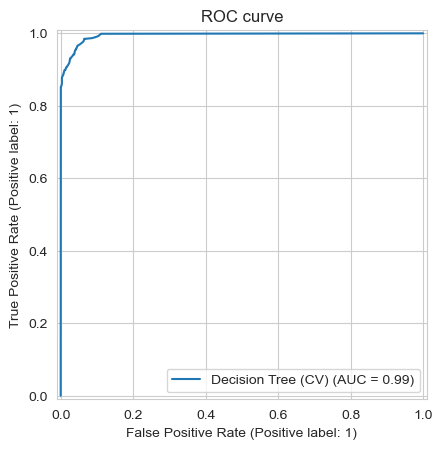

In [16]:
# Poison probabilities of the best model from cross-validation
cv_probs = cross_val_predict(gs.best_estimator_, X_train, y_train,
                             cv=splitter, method="predict_proba")[:, 1]

RocCurveDisplay.from_predictions(y_train, cv_probs, name="Decision Tree (CV)")
plt.title("ROC curve")
plt.show()

In [17]:
fpr, tpr, thresholds = roc_curve(y_train, cv_probs)

roc_df = pd.DataFrame({
    "False Positive Rate": fpr,
    "True Positive Rate": tpr,
    "Threshold": thresholds,
})
# Easier to read: convert rates into numbers of mushrooms
roc_df["Kills"] = ((1 - tpr) * (y_train == 1).sum()).round().astype(int)
roc_df["Uneaten"] = (fpr * (y_train == 0).sum()).round().astype(int)

# The most cautious thresholds are at the end of the table
roc_df.tail(12).round(4)

,False Positive Rate,True Positive Rate,Threshold,Kills,Uneaten
88,0.0838,0.9865,0.2353,34,224
89,0.0849,0.9865,0.2338,34,227
90,0.0887,0.9873,0.2286,32,237
91,0.0917,0.9881,0.2273,30,245
92,0.0939,0.9889,0.2222,28,251
93,0.1018,0.9917,0.2206,21,272
94,0.1048,0.9929,0.2174,18,280
95,0.1055,0.9941,0.2000,15,282
96,0.1074,0.9956,0.1972,11,287
97,0.1096,0.9972,0.1970,7,293


**How to read the table (bottom to top)**
- **Last row, threshold 0:** "throw everything away". Zero kills, but all 2673 edible mushrooms are gone.
- **Row above:** the most cautious setting that still makes sense. Every mushroom with a poison probability above 0 counts as poisonous. Result: **3 kills, 298 uneaten** (for 5199 mushrooms).
- **Further up:** even slightly higher thresholds cost lives immediately – 15 kills at 0.20, more than 20 at 0.22.

**Blind spots:** the 3 remaining kills have a poison probability of 0. These mushrooms are poisonous but look exactly like mushrooms that were always edible in the respective training part. No threshold can save them – other than throwing everything away.

## 8. Cost function and threshold with nested CV

Instead of reading the threshold off the table by hand, we tell the computer **what an error costs us** and let it search for the threshold.

### 8.1 The cost function

- An edible mushroom thrown away costs **1**.
- A kill costs **`poison_cost`**.

Our value: **`poison_cost = 100`**. One kill weighs as much as 100 edible mushrooms thrown away. Section 8.3 shows why exactly this value and not an even higher one.

In [18]:
def cost_balance(y_true, y_pred, poison_cost=100, missed_food_cost=1):
    # Count errors (labels=[0, 1] keeps the matrix 2x2 even in small folds)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    # Multiply errors by their costs
    total_error = (fp * missed_food_cost) + (fn * poison_cost)
    # Return the negative: sklearn always tries to maximise the score
    return -total_error

# Turn the function into an sklearn scorer
cost_balance_score = make_scorer(cost_balance)

### 8.2 Threshold with nested CV

`TunedThresholdClassifierCV` searches for the threshold with the lowest cost. To keep the threshold from overfitting a single split, we wrap this in a second cross-validation (**nested CV**) and **average** the thresholds found.

In [19]:
inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)  # searches the threshold
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=2)  # repeats the search on other data

def find_threshold(model, scorer, X_data, y_data):
    # Searches the threshold again in every outer fold and returns the mean and the single values
    threshold_tuner = TunedThresholdClassifierCV(estimator=model, scoring=scorer, cv=inner_cv)
    cv_results = cross_validate(threshold_tuner, X_data, y_data, cv=outer_cv, return_estimator=True)
    fold_thresholds = [estimator.best_threshold_ for estimator in cv_results["estimator"]]
    return float(np.mean(fold_thresholds)), fold_thresholds

cv_tuned_threshold, fold_thresholds = find_threshold(gs.best_estimator_, cost_balance_score, X_train, y_train)
print("Thresholds of the 5 outer folds:", np.round(fold_thresholds, 4))
print("Averaged threshold:", round(cv_tuned_threshold, 4))

Thresholds of the 5 outer folds: [0.0101 0.0101 0.0101 0.0101 0.0101]
Averaged threshold: 0.0101


### 8.3 How sensitive is the result to the costs?

We repeat the search with different costs for a kill. This shows how the cost setting affects threshold and errors.

In [20]:
rows = []
for poison_cost in [1, 5, 10, 100, 1000, 10000]:
    scorer = make_scorer(cost_balance, poison_cost=poison_cost)
    threshold, per_fold = find_threshold(gs.best_estimator_, scorer, X_train, y_train)
    # Apply the threshold to the CV probabilities from section 7
    b = evaluate(y_train, (cv_probs > threshold).astype(int))
    rows.append({
        "Cost kill : uneaten": f"{poison_cost} : 1",
        "Threshold (mean)": round(threshold, 4),
        "Thresholds per fold": np.round(per_fold, 3),
        "Folds choosing 'discard everything'": int(np.sum(np.array(per_fold) == 0)),
        "Kills (CV)": b["Kills (FN)"],
        "Uneaten (CV)": b["Uneaten (FP)"],
        "Accuracy": b["Accuracy"],
    })
pd.DataFrame(rows).set_index("Cost kill : uneaten")

,Threshold (mean),Thresholds per fold,Folds choosing 'discard everything',Kills (CV),Uneaten (CV),Accuracy
Cost kill : uneaten,,,,,,
1 : 1,0.3354,"[0.283, 0.333, 0.333, 0.242, 0.485]",0,38,173,0.9594
5 : 1,0.0101,"[0.01, 0.01, 0.01, 0.01, 0.01]",0,3,298,0.9421
10 : 1,0.0101,"[0.01, 0.01, 0.01, 0.01, 0.01]",0,3,298,0.9421
100 : 1,0.0101,"[0.01, 0.01, 0.01, 0.01, 0.01]",0,3,298,0.9421
1000 : 1,0.0020,"[0.0, 0.01, 0.0, 0.0, 0.0]",4,3,298,0.9421
10000 : 1,0.0000,"[0.0, 0.0, 0.0, 0.0, 0.0]",5,3,298,0.9421


**Result**
- **1 : 1** (both errors equally bad): threshold 0.34, highest accuracy (0.959), but 38 kills. This is what you get when optimising for accuracy.
- **5 : 1 to 100 : 1:** always the same threshold 0.01 and the same result (3 kills, 298 uneaten). In this range the choice is **robust** – it does not matter whether a kill is worth 5 or 100 mushrooms.
- **1000 : 1 and above:** in 4 and 5 of 5 folds respectively, the tuner picks threshold 0, i.e. "discard everything". The blind spots are the reason: if a kill costs 1000 and cannot be prevented, it is mathematically cheaper to eat no mushroom at all. (The kills/uneaten columns still show 3 / 298 there because the averaged threshold sits just above 0. The honest reading of those rows is "discard everything".)

**Our choice: 100 : 1.** This is the highest price for a kill at which the model stays useful. A model that discards everything would score 0 deaths and 866 uneaten on the leaderboard – worse than the sample submission with 660.

## 9. Caution versus yield: the finalists

The threshold is now as cautious as it can be. A second dial remains: **`min_samples_leaf`**.

- `min_samples_leaf = 1` (full tree): the tree trusts even a combination it has seen **only once**. If that one mushroom was edible, the combination counts as edible.
- Larger values: rare combinations no longer get their own verdict. They are judged together with similar mushrooms. If there is a poisonous one among them, the whole group counts as poisonous. That is **more cautious** but costs edible mushrooms.

AUC could not tell these settings apart. So we measure directly what matters: **kills and uneaten**. To avoid depending on a single split, we repeat the 10-fold cross-validation with 5 different shuffles (50 runs per setting).

In [21]:
n_repeats = 5
rows = []
for msl in [1, 2, 3, 5, 8, 10, 15, 20, 30]:
    # Take the best model from the grid search and change only min_samples_leaf
    model = clone(gs.best_estimator_).set_params(decisiontreeclassifier__min_samples_leaf=msl)
    kills, uneaten = [], []
    for seed in range(n_repeats):
        cv_seed = StratifiedKFold(n_splits=10, shuffle=True, random_state=seed)
        probs = cross_val_predict(model, X_train, y_train, cv=cv_seed, method="predict_proba")[:, 1]
        b = evaluate(y_train, (probs > cv_tuned_threshold).astype(int))
        kills.append(b["Kills (FN)"])
        uneaten.append(b["Uneaten (FP)"])
    rows.append({
        "min_samples_leaf": msl,
        "Total kills (5 repeats)": int(np.sum(kills)),
        "Kills per 1625": round(np.mean(kills) * SCALE, 2),
        "Uneaten per 1625": round(np.mean(uneaten) * SCALE, 1),
    })

caution_curve = pd.DataFrame(rows)
# Expected total cost per 1625 mushrooms at two different prices for a kill
for price in [100, 1000]:
    caution_curve[f"Cost at {price}:1"] = (
        caution_curve["Kills per 1625"] * price + caution_curve["Uneaten per 1625"]
    ).round(0)
caution_curve

,min_samples_leaf,Total kills (5 repeats),Kills per 1625,Uneaten per 1625,Cost at 100:1,Cost at 1000:1
0,1,6,0.38,94.2,132.0,474.0
1,2,6,0.38,95.0,133.0,475.0
2,3,5,0.31,96.3,127.0,406.0
3,5,9,0.56,103.4,159.0,663.0
4,8,7,0.44,118.3,162.0,558.0
5,10,6,0.38,125.7,164.0,506.0
6,15,4,0.25,140.3,165.0,390.0
7,20,1,0.06,159.8,166.0,220.0
8,30,1,0.06,170.4,176.0,230.0


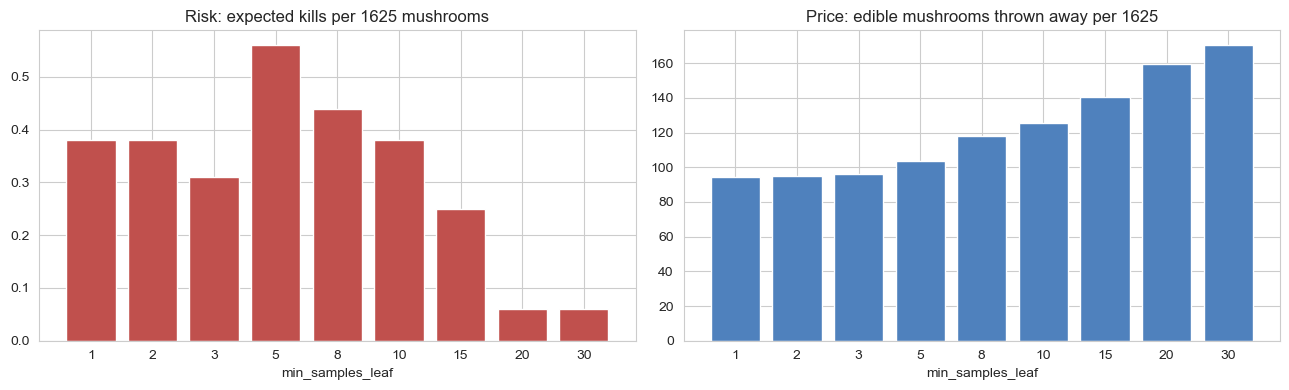

In [22]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
x_pos = range(len(caution_curve))

ax1.bar(x_pos, caution_curve["Kills per 1625"], color="#c0504d")
ax1.set_title("Risk: expected kills per 1625 mushrooms")

ax2.bar(x_pos, caution_curve["Uneaten per 1625"], color="#4f81bd")
ax2.set_title("Price: edible mushrooms thrown away per 1625")

for ax in (ax1, ax2):
    ax.set_xticks(list(x_pos))
    ax.set_xticklabels(caution_curve["min_samples_leaf"])
    ax.set_xlabel("min_samples_leaf")
plt.tight_layout()
plt.show()

**Result**
- More caution is expensive and only works late: up to `min_samples_leaf=10` the kills stay about the same (5 to 9 in 50 runs), yet 30 more mushrooms are already thrown away. Only from 20 onwards does the risk drop clearly (1 kill) – at 160 instead of 94 mushrooms thrown away.
- Which setting is best depends on the price of a kill: at **100 : 1** the full tree is cheapest (cost around 130 versus 166). At **1000 : 1** `min_samples_leaf=20` wins (220 versus 474). The switch happens at roughly 200 : 1.
- Caveat: these differences rest on a handful of individual poisonous mushrooms. The numbers show a tendency, not a certainty.

This gives us four finalists.

In [23]:
# Finalist A: the best model according to the grid search (AUC), threshold from section 8
model_A = clone(gs.best_estimator_)
threshold_A = cv_tuned_threshold

# Finalist B: same tree, but as cautious as is cheapest at a kill price of 1000:1
msl_cautious = int(caution_curve.sort_values(["Cost at 1000:1", "min_samples_leaf"])["min_samples_leaf"].iloc[0])
model_B = clone(gs.best_estimator_).set_params(decisiontreeclassifier__min_samples_leaf=msl_cautious)
threshold_B, folds_B = find_threshold(model_B, cost_balance_score, X_train, y_train)

# Finalist C: second model family (random forest), threshold also found via the cost function
model_C = build_pipeline(RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1))
threshold_C, folds_C = find_threshold(model_C, cost_balance_score, X_train, y_train)

# Finalist D: the same random forest with a hand-set, extra cautious threshold.
# A 5 % poison probability is already enough for 'poisonous'.
model_D = clone(model_C)
threshold_D = 0.05

print(f"A  full tree (min_samples_leaf={gs.best_params_['decisiontreeclassifier__min_samples_leaf']}): threshold {threshold_A:.4f}")
print(f"B  cautious tree (min_samples_leaf={msl_cautious}): threshold {threshold_B:.4f}  | per fold: {np.round(folds_B, 3)}")
print(f"C  random forest: threshold {threshold_C:.4f}  | per fold: {np.round(folds_C, 3)}")
print(f"D  random forest, extra cautious: threshold {threshold_D:.4f} (set by hand)")

finalists = {
    "A": ("Full decision tree", model_A, threshold_A),
    "B": (f"Cautious decision tree (min_samples_leaf={msl_cautious})", model_B, threshold_B),
    "C": ("Random forest, threshold via cost function", model_C, threshold_C),
    "D": ("Random forest, extra cautious threshold", model_D, threshold_D),
}

A  full tree (min_samples_leaf=1): threshold 0.0101
B  cautious tree (min_samples_leaf=20): threshold 0.0404  | per fold: [0.03  0.051 0.01  0.01  0.101]
C  random forest: threshold 0.1354  | per fold: [0.192 0.141 0.172 0.162 0.01 ]
D  random forest, extra cautious: threshold 0.0500 (set by hand)


### All finalists side by side

Same measurement as above (5 × 10-fold cross-validation), now for all four finalists with their respective thresholds.

In [24]:
# Compute the probabilities once per model and repeat (C and D share the same forest)
cv_probabilities = {}
for key in ["A", "B", "C"]:
    model = finalists[key][1]
    cv_probabilities[key] = [
        cross_val_predict(model, X_train, y_train,
                          cv=StratifiedKFold(n_splits=10, shuffle=True, random_state=seed),
                          method="predict_proba")[:, 1]
        for seed in range(n_repeats)
    ]
cv_probabilities["D"] = cv_probabilities["C"]

rows = []
for key, (name, model, threshold) in finalists.items():
    kills = [evaluate(y_train, (p > threshold).astype(int))["Kills (FN)"] for p in cv_probabilities[key]]
    uneaten = [evaluate(y_train, (p > threshold).astype(int))["Uneaten (FP)"] for p in cv_probabilities[key]]
    kills_1625, uneaten_1625 = np.mean(kills) * SCALE, np.mean(uneaten) * SCALE
    rows.append({
        "Variant": key,
        "Model": name,
        "Total kills (5 repeats)": int(np.sum(kills)),
        "Kills per 1625": round(kills_1625, 2),
        "Uneaten per 1625": round(uneaten_1625, 1),
        "Cost at 100:1": round(kills_1625 * 100 + uneaten_1625),
        "Cost at 1000:1": round(kills_1625 * 1000 + uneaten_1625),
    })
finalists_cv = pd.DataFrame(rows).set_index("Variant")
finalists_cv

,Model,Total kills (5 repeats),Kills per 1625,Uneaten per 1625,Cost at 100:1,Cost at 1000:1
Variant,,,,,,
A,Full decision tree,6,0.38,94.2,132,469
B,Cautious decision tree (min_samples_leaf=20),2,0.13,155.9,168,281
C,"Random forest, threshold via cost function",2,0.13,96.0,109,221
D,"Random forest, extra cautious threshold",2,0.13,98.6,111,224


**Result**
- **A (full tree)** throws away the least (94) but carries the highest risk: 6 kills in 50 runs, i.e. 0.38 per 1625 mushrooms. Put differently: roughly **every third test set** of this size contains a kill.
- **C and D (random forest)** throw away only 2 to 4 mushrooms more and had 2 kills. According to the cost function **C is the best finalist** (cost 109 versus 132 for A). A forest is naturally a bit more cautious: it consists of 200 trees that each see different parts of the data. If only some of them have doubts, the poison probability is already above 0.
- **B (cautious tree)** is not worth it: far more thrown away (156), yet in this measurement no safer than C and D.
- Here too: the gap between 2 and 6 kills rests on individual mushrooms.

## 10. Check on held-out data

Now we use the 20 % hold-out set – for the first and only time. The models have never seen these mushrooms.

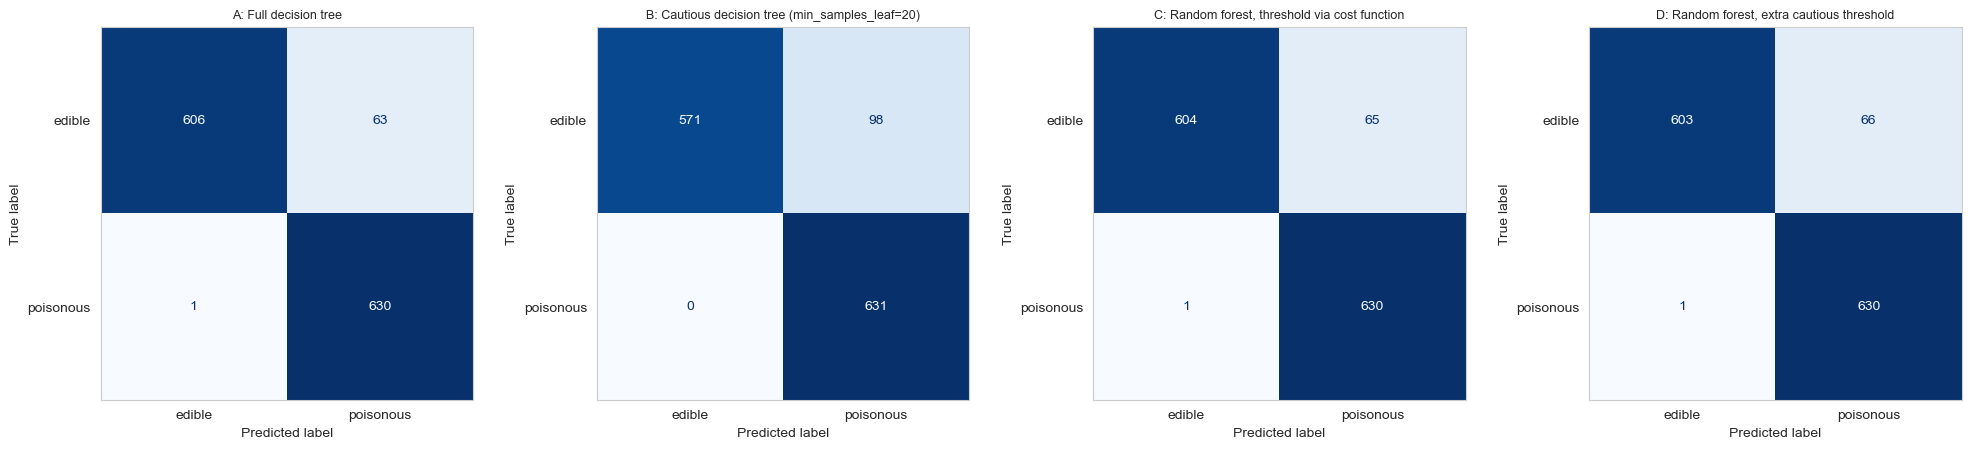

,Model,Kills (FN),Uneaten (FP),Recall,Accuracy
Variant,,,,,
A,Full decision tree,1,63,0.9984,0.9508
B,Cautious decision tree (min_samples_leaf=20),0,98,1.0000,0.9246
C,"Random forest, threshold via cost function",1,65,0.9984,0.9492
D,"Random forest, extra cautious threshold",1,66,0.9984,0.9485


In [25]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
rows = []
for ax, (key, (name, model, threshold)) in zip(axes, finalists.items()):
    model.fit(X_train, y_train)
    test_probs = model.predict_proba(X_test)[:, 1]
    test_preds = (test_probs > threshold).astype(int)

    rows.append({"Variant": key, "Model": name, **evaluate(y_test, test_preds)})
    ConfusionMatrixDisplay.from_predictions(
        y_test, test_preds, display_labels=["edible", "poisonous"], cmap="Blues", colorbar=False, ax=ax
    )
    ax.set_title(f"{key}: {name}", fontsize=9)
    ax.grid(False)
plt.tight_layout()
plt.show()

holdout_results = pd.DataFrame(rows).set_index("Variant")
holdout_results

**Result**
- A, C and D each have **1 kill** on the hold-out set. That is a blind spot: a poisonous mushroom whose combination only appeared as edible in training. The residual risk from cross-validation is real.
- B has 0 kills but throws away 98 instead of 63 to 66 edible mushrooms.
- For the competition we train on all 6499 mushrooms instead of 5199. More data means fewer blind spots. The risk drops a little but does not disappear.

**Consequence:** "zero kills" cannot be guaranteed with these 6 features, only made likely.

## 11. Which features does the model use?

The decision tree provides an **importance** for every one-hot column: how much did it contribute to separating poisonous from edible? We add up the columns per original feature.

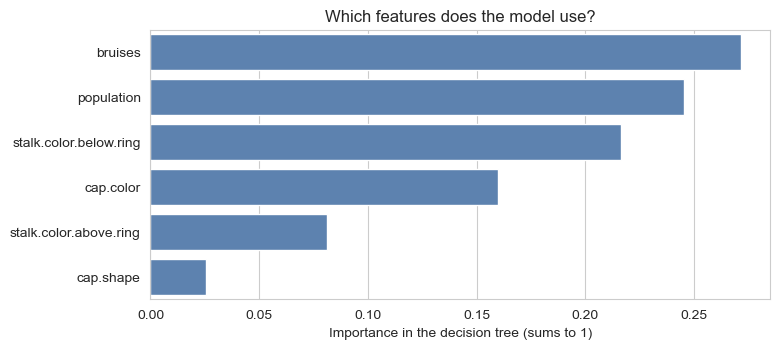

Importance per feature:
feature
bruises                   0.272
population                0.246
stalk.color.below.ring    0.216
cap.color                 0.160
stalk.color.above.ring    0.081
cap.shape                 0.026

The 8 most important single columns:
                  column  importance
               bruises_t       0.272
stalk.color.below.ring_w       0.208
            population_v       0.185
             cap.color_n       0.053
stalk.color.above.ring_o       0.046
             cap.color_y       0.041
stalk.color.above.ring_w       0.029
            population_n       0.026

The tree has 54 leaves and is 15 levels deep.


In [26]:
# Train the full decision tree on all training data
model_A.fit(X, y)
tree = model_A[-1]                                # last step of the pipeline = the tree
columns = model_A[:-1].get_feature_names_out()    # names of the one-hot columns, e.g. 'cap.color_n'

importance = pd.DataFrame({"column": columns, "importance": tree.feature_importances_})
# 'cap.color_n' -> feature 'cap.color'
importance["feature"] = importance["column"].str.rsplit("_", n=1).str[0]

per_feature = importance.groupby("feature")["importance"].sum().sort_values(ascending=False)

plt.figure(figsize=(8, 3.5))
sns.barplot(x=per_feature.values, y=per_feature.index, color="#4f81bd")
plt.xlabel("Importance in the decision tree (sums to 1)")
plt.ylabel("")
plt.title("Which features does the model use?")
plt.show()

print("Importance per feature:")
print(per_feature.round(3).to_string())
print("\nThe 8 most important single columns:")
print(importance.sort_values("importance", ascending=False).head(8)[["column", "importance"]].round(3).to_string(index=False))
print(f"\nThe tree has {tree.get_n_leaves()} leaves and is {tree.get_depth()} levels deep.")

**Result**
- Most important are **bruises** (27 %), **population** (25 %) and the **stalk colour below the ring** (22 %). **Cap shape** hardly matters at 3 %.
- The stalk colour above the ring looks unimportant at 8 %, although the stalk colours gave the clearest signals in section 3.2. The reason: both stalk colours carry almost the same information. Once the tree has used one, the other adds little.
- Importance is not the same as "points to poisonous". It only says how much a feature helps to **separate** – in both directions. The direction is shown by the poison-rate table in section 3.2.

## 12. Create submission files

Each finalist is trained on **all** training data and then predicts the competition mushrooms.

**Format check:** every file is automatically compared with `sample_submission.csv`. If something is off, the cell stops with an error message before a wrong file gets uploaded.

**Estimate in advance:** the leaderboard reveals how many edible mushrooms the competition set contains. The sample submission labels 206 mushrooms as edible and scores 0 deaths and 660 uneaten on the leaderboard. So there are 206 + 660 = **866** edible mushrooms. For every submission this gives:

> uneaten = 866 − (number of mushrooms labelled edible) + deaths

**Safety check:** the column "edible despite poison in training" counts mushrooms labelled edible although their combination was poisonous at least once in training. It must be 0 for every variant.

In [27]:
N_EDIBLE_IN_COMPETITION = 866  # derived from the leaderboard, see text above

def check_format(submission, sample):
    # Compares the submission with the sample file and reports deviations as errors
    candidate = submission.reset_index()
    if list(candidate.columns) != list(sample.columns):
        raise ValueError(f"Wrong columns: {list(candidate.columns)} instead of {list(sample.columns)}")
    if len(candidate) != len(sample):
        raise ValueError(f"Wrong number of rows: {len(candidate)} instead of {len(sample)}")
    if not (candidate["Id"].values == sample["Id"].values).all():
        raise ValueError("The Ids do not match the sample file (order or content).")
    if not set(candidate["poisonous"].unique()) <= {0, 1}:
        raise ValueError("'poisonous' may only contain 0 and 1.")
    return True

rows = []
predictions = {}
for key, (name, model, threshold) in finalists.items():
    # Deployment: train on all training data
    model.fit(X, y)

    comp_probs = model.predict_proba(X_comp)[:, 1]
    comp_preds = (comp_probs > threshold).astype(int)
    predictions[key] = comp_preds

    submission = pd.DataFrame({"poisonous": comp_preds}, index=X_comp.index)
    check_format(submission, sample_submission)

    file_name = f"submission_{key}.csv"
    submission.to_csv(os.path.join(OUTPUT_DIR, file_name))

    n_edible = int((comp_preds == 0).sum())
    # Safety check: is a mushroom labelled edible although its combination
    # was poisonous at least once in training? That should never happen.
    poison_in_training = comp_combos["poisonous"].fillna(0).values > 0
    n_reckless = int(((comp_preds == 0) & poison_in_training).sum())
    rows.append({
        "Variant": key,
        "Model": name,
        "Threshold": round(threshold, 4),
        "File": file_name,
        "predicted edible": n_edible,
        "expected uneaten at 0 deaths": N_EDIBLE_IN_COMPETITION - n_edible,
        "edible despite poison in training": n_reckless,
    })

submissions = pd.DataFrame(rows).set_index("Variant")
print("All files passed the format check and were written to:", OUTPUT_DIR)
submissions

All files passed the format check and were written to: submissions


,Model,Threshold,File,predicted edible,expected uneaten at 0 deaths,edible despite poison in training
Variant,,,,,,
A,Full decision tree,0.0101,submission_A.csv,780,86,0
B,Cautious decision tree (min_samples_leaf=20),0.0404,submission_B.csv,741,125,0
C,"Random forest, threshold via cost function",0.1354,submission_C.csv,779,87,0
D,"Random forest, extra cautious threshold",0.0500,submission_D.csv,776,90,0


### How do the variants differ?

The variants agree on almost every mushroom. Listed here are the mushrooms on which they disagree. The residual risk of the bolder variants sits exactly in these mushrooms.

In [28]:
differences = X_comp.copy()
for key in finalists:
    differences[key] = np.where(predictions[key] == 1, "poisonous", "edible")

# Only mushrooms on which the variants disagree
disagreement = differences[differences[list(finalists)].nunique(axis=1) > 1]
print("Competition mushrooms on which the variants disagree:", len(disagreement), "of", len(X_comp))

# Summarise per combination and put the training record next to it
disputed = (disagreement.groupby(features + list(finalists)).size().rename("mushrooms in competition").reset_index()
            .merge(combos[features + ["count", "poisonous"]], on=features, how="left")
            .rename(columns={"count": "seen in training", "poisonous": "of which poisonous"})
            .sort_values(["seen in training"] + features))
disputed.reset_index(drop=True)

Competition mushrooms on which the variants disagree: 39 of 1625


,cap.shape,cap.color,bruises,stalk.color.above.ring,stalk.color.below.ring,population,A,B,C,D,mushrooms in competition,seen in training,of which poisonous
0,f,c,t,w,w,v,edible,poisonous,poisonous,poisonous,1,1,0
1,f,n,f,n,n,y,edible,poisonous,edible,poisonous,3,1,0
2,k,b,t,w,w,c,edible,poisonous,edible,edible,2,2,0
3,f,b,t,w,w,c,edible,poisonous,edible,edible,1,3,0
4,f,p,t,w,w,c,edible,poisonous,edible,edible,1,3,0
5,f,w,f,w,w,v,edible,poisonous,edible,edible,1,3,0
6,k,n,t,w,w,c,edible,poisonous,edible,edible,1,3,0
7,k,p,t,w,w,c,edible,poisonous,edible,edible,1,3,0
8,x,b,t,w,w,c,edible,poisonous,edible,edible,1,3,0
9,x,r,f,w,w,v,edible,poisonous,edible,edible,1,3,0


In [29]:
# Check whether the variants are nested:
# every mushroom the more cautious variant eats is also eaten by the bolder one.
for cautious, bold in [("B", "D"), ("D", "C"), ("C", "A")]:
    eats_cautious = predictions[cautious] == 0
    eats_bold = predictions[bold] == 0
    nested = bool((eats_bold | ~eats_cautious).all())
    print(f"Everything {cautious} eats, {bold} eats too: {nested}")

Everything B eats, D eats too: True
Everything D eats, C eats too: True
Everything C eats, A eats too: True


**Result**
- On 1586 of 1625 mushrooms all four variants agree.
- **A versus C:** a single mushroom (flat, cinnamon) whose combination appeared only once in training.
- **C versus D:** three mushrooms with a brown stalk above and below the ring. The combination appeared once in training and was edible – but a brown stalk was otherwise 96 % poisonous. Exactly the kind of combination where caution makes sense.
- **B** throws away another 35 mushrooms, 21 of them from a combination that appeared 43 times in training and was never poisonous. That is overcautious and explains why B is so much more expensive.

The variants are **nested**: what B eats, D eats too; what D eats, C eats too; what C eats, A eats too. If a more cautious variant has a death, every bolder one has it as well.

## 13. First upload and second round

**Result of the first upload (variant C): 2 deaths, 89 uneaten.**

- The estimate from section 12 holds: 866 − 779 + 2 = 89.
- Among the 779 mushrooms labelled edible there were two poisonous ones. These are blind spots, just as cross-validation and the hold-out set had announced.

**What next?** Trying out individual mushrooms on the leaderboard would mean overfitting the test set. Instead we go back to cross-validation: for the random forest we have so far only tuned the threshold, not the hyperparameters. We do that now – this time directly with the leaderboard's criterion:

1. first: **not a single kill** in all 50 CV runs,
2. then: as few mushrooms thrown away as possible.

We vary `min_samples_leaf` and the threshold. The cell takes one to three minutes.

In [30]:
rows = []
for msl in [1, 2, 3, 5]:
    forest = build_pipeline(RandomForestClassifier(n_estimators=200, min_samples_leaf=msl,
                                                   random_state=42, n_jobs=-1))
    if msl == 1:
        # We already computed this forest in section 9 (variant C)
        probabilities = cv_probabilities["C"]
    else:
        probabilities = [
            cross_val_predict(forest, X_train, y_train,
                              cv=StratifiedKFold(n_splits=10, shuffle=True, random_state=seed),
                              method="predict_proba")[:, 1]
            for seed in range(n_repeats)
        ]
    for threshold in [0.05, 0.10, 0.15, 0.20]:
        results = [evaluate(y_train, (p > threshold).astype(int)) for p in probabilities]
        rows.append({
            "min_samples_leaf": msl,
            "Threshold": threshold,
            "Total kills (50 runs)": int(np.sum([b["Kills (FN)"] for b in results])),
            "Uneaten per 1625": round(np.mean([b["Uneaten (FP)"] for b in results]) * SCALE, 1),
        })

grid_rf = pd.DataFrame(rows)
grid_rf

,min_samples_leaf,Threshold,Total kills (50 runs),Uneaten per 1625
0,1,0.05,2,98.6
1,1,0.10,2,96.5
2,1,0.15,6,96.0
3,1,0.20,29,93.5
4,2,0.05,0,132.0
5,2,0.10,0,113.4
6,2,0.15,2,104.8
7,2,0.20,33,96.9
8,3,0.05,0,153.0
9,3,0.10,0,124.3


In [31]:
# Selection following the leaderboard's ranking: zero kills first, then as little waste as possible
zero_kills = grid_rf[grid_rf["Total kills (50 runs)"] == 0]
if len(zero_kills) == 0:
    # Error handling: without candidates the code below would fail with a cryptic index error
    raise ValueError("No setting without kills found. Please extend the grid.")

best = zero_kills.sort_values("Uneaten per 1625").iloc[0]
msl_E = int(best["min_samples_leaf"])
threshold_E = float(best["Threshold"])
print(f"Variant E: random forest with min_samples_leaf={msl_E} and threshold {threshold_E}")
print(f"In CV: 0 kills in 50 runs, {best['Uneaten per 1625']} uneaten per 1625 mushrooms")

model_E = build_pipeline(RandomForestClassifier(n_estimators=200, min_samples_leaf=msl_E,
                                                random_state=42, n_jobs=-1))

# Cross-check on the hold-out set. It was already used once in section 10,
# so it is no longer fully untouched, but it still serves as a rough cross-check.
model_E.fit(X_train, y_train)
test_preds_E = (model_E.predict_proba(X_test)[:, 1] > threshold_E).astype(int)
print("Hold-out set:", evaluate(y_test, test_preds_E))

Variant E: random forest with min_samples_leaf=2 and threshold 0.1
In CV: 0 kills in 50 runs, 113.4 uneaten per 1625 mushrooms
Hold-out set: {'Kills (FN)': 0, 'Uneaten (FP)': 75, 'Recall': 1.0, 'Accuracy': 0.9423}


**Result**
- The previous forest (`min_samples_leaf=1`) has kills in cross-validation at **every** threshold.
- With `min_samples_leaf=2` and threshold 0.10 there is **no kill in 50 runs** and none on the hold-out set either. Among all settings without kills, this one throws away the least.
- The price: about 113 instead of 96 mushrooms thrown away per 1625.

**Why does `min_samples_leaf=2` help?** The trees may no longer split all the way down to a single mushroom. Rare combinations therefore end up in the same leaf as their most similar neighbours. If there are poisonous mushrooms among them, the poison probability rises above the threshold. A single edible mushroom is no longer enough proof of "edible".

In [32]:
# Deployment of variant E: train on all training data and write the submission file
model_E.fit(X, y)
comp_preds_E = (model_E.predict_proba(X_comp)[:, 1] > threshold_E).astype(int)
predictions["E"] = comp_preds_E

submission_E = pd.DataFrame({"poisonous": comp_preds_E}, index=X_comp.index)
check_format(submission_E, sample_submission)
submission_E.to_csv(os.path.join(OUTPUT_DIR, "submission_E.csv"))

n_edible_E = int((comp_preds_E == 0).sum())
submissions.loc["E"] = pd.Series({
    "Model": f"Random forest, min_samples_leaf={msl_E}, 0 kills in CV",
    "Threshold": threshold_E,
    "File": "submission_E.csv",
    "predicted edible": n_edible_E,
    "expected uneaten at 0 deaths": N_EDIBLE_IN_COMPETITION - n_edible_E,
    "edible despite poison in training": int(((comp_preds_E == 0) & (comp_combos["poisonous"].fillna(0).values > 0)).sum()),
})
submissions

,Model,Threshold,File,predicted edible,expected uneaten at 0 deaths,edible despite poison in training
Variant,,,,,,
A,Full decision tree,0.0101,submission_A.csv,780,86,0
B,Cautious decision tree (min_samples_leaf=20),0.0404,submission_B.csv,741,125,0
C,"Random forest, threshold via cost function",0.1354,submission_C.csv,779,87,0
D,"Random forest, extra cautious threshold",0.0500,submission_D.csv,776,90,0
E,"Random forest, min_samples_leaf=2, 0 kills in CV",0.1000,submission_E.csv,771,95,0


In [33]:
# What does E additionally throw away that C still ate?
eats_C = predictions["C"] == 0
eats_E = predictions["E"] == 0
print("Everything E eats, C eats too:", bool((eats_C | ~eats_E).all()))
print("Mushrooms that C eats and E throws away:", int((eats_C & ~eats_E).sum()))

additional = (X_comp[eats_C & ~eats_E].groupby(features).size().rename("mushrooms in competition").reset_index()
              .merge(combos[features + ["count", "poisonous"]], on=features, how="left")
              .rename(columns={"count": "seen in training", "poisonous": "of which poisonous"})
              .sort_values("seen in training"))
additional.reset_index(drop=True)

Everything E eats, C eats too: True
Mushrooms that C eats and E throws away: 8


,cap.shape,cap.color,bruises,stalk.color.above.ring,stalk.color.below.ring,population,mushrooms in competition,seen in training,of which poisonous
0,f,n,f,n,n,y,3,1,0
1,f,w,f,w,w,v,1,3,0
2,x,r,f,w,w,v,1,3,0
3,x,u,f,w,w,v,1,3,0
4,f,n,f,w,n,v,2,8,0


**Result**
- E eats nothing that C did not eat as well, and throws away 8 more mushrooms. All 8 come from **rare combinations** (seen at most 8 times in training).
- If the two poisonous mushrooms from the first upload are among these 8, E has **0 deaths and 95 uneaten**.
- **The second upload confirmed exactly that: 0 deaths, 95 uneaten.** So the two poisonous mushrooms are among these 8.
- One combination stands out: flat / brown / no bruises / stalk white above and brown below the ring / several. Its siblings with a different cap shape (convex, knobbed) contained poisonous mushrooms in training – and exactly this family caused all the kills in cross-validation.

## 14. Upload log

**Order**
1. **C** – done: 2 deaths, 89 uneaten.
2. **E** – done: 0 deaths, 95 uneaten. Exactly as computed in advance.
3. **D** – done: 2 deaths, 92 uneaten. D only throws away the 3 brown-stalk mushrooms on top of C. So the two poisonous mushrooms are not among those, but among the other 5 that E throws away additionally.

The leaderboard keeps the **best** result: E counts, with 0 deaths and 95 uneaten.

Further attempts would be guessing on the leaderboard, not modelling.

A is not uploaded: A eats everything C eats and would have the same 2 deaths. B is no longer needed.

In [34]:
# Actual results from the leaderboard (None = not uploaded yet)
uploads = [
    {"No": 1, "Variant": "C", "Deaths": 2, "Uneaten": 89},
    {"No": 2, "Variant": "E", "Deaths": 0, "Uneaten": 95},
    {"No": 3, "Variant": "D", "Deaths": 2, "Uneaten": 92},
]

log = pd.DataFrame(uploads)
log[["Deaths", "Uneaten"]] = log[["Deaths", "Uneaten"]].astype("Int64")  # whole numbers, gaps allowed
log["Model"] = log["Variant"].map(submissions["Model"])
log["File"] = log["Variant"].map(submissions["File"])
log["Expected at 0 deaths"] = log["Variant"].map(submissions["expected uneaten at 0 deaths"])
# Cross-check with the formula from section 12: uneaten = 866 - predicted edible + deaths
log["Recomputed"] = (N_EDIBLE_IN_COMPETITION
                     - log["Variant"].map(submissions["predicted edible"])
                     + log["Deaths"])
log[["No", "Variant", "Model", "File", "Expected at 0 deaths", "Deaths", "Uneaten", "Recomputed"]].set_index("No")

,Variant,Model,File,Expected at 0 deaths,Deaths,Uneaten,Recomputed
No,,,,,,,
1,C,"Random forest, threshold via cost function",submission_C.csv,87,2,89,89
2,E,"Random forest, min_samples_leaf=2, 0 kills in CV",submission_E.csv,95,0,95,95
3,D,"Random forest, extra cautious threshold",submission_D.csv,90,2,92,92


## 15. Summary

### What the data can give
- 6499 training and 1625 competition mushrooms, 6 visible features, all categorical, no gaps, balanced classes.
- There are only 378 distinct feature combinations. In 18 of them poisonous and edible mushrooms look identical.
- Consequence: zero kills inevitably cost around 80 edible mushrooms in the competition. That is why everyone ends up at 80 to 95 "uneaten".

### Which features point to "poisonous"
- Stalk colour `buff`, `cinnamon` or `brown`: almost always poisonous. `gray`, `orange`, `red`: never in training.
- No bruises: about 70 % poisonous (with bruises about 20 %).
- Population `several`: about 70 % poisonous. `abundant` and `numerous`: never.
- A single feature is never enough for "edible" – only the combination decides.

### What I tried

| Experiment | Result |
|---|---|
| Baseline: decision tree, threshold 0.5 | accuracy 0.959, but 91 kills in CV (about 28 in the competition) |
| 4 model families | decision tree and random forest ahead, logistic regression far behind |
| One-hot versus ordinal | no difference |
| Grid search over 50 settings (AUC) and stability check | full tree wins consistently, but the best settings are tied |
| ROC curve | threshold just above 0 needed; 3 blind spots remain |
| Cost ratios 1:1 to 10000:1 | same threshold from 5:1 upwards; "discard everything" from 1000:1 |
| `min_samples_leaf` for the decision tree | expensive and only effective from 20 |
| Random forest with threshold via cost function (C) | cheapest in CV – but 2 deaths on the leaderboard |
| Random forest: `min_samples_leaf` × threshold, criterion "zero kills first" (E) | 0 kills in 50 CV runs and on the hold-out set |

### How I defined the evaluation
- **Not accuracy:** the best accuracy (0.959) comes with 38 kills.
- **AUC** for the decision tree settings because it does not depend on the threshold.
- **Cost function** for the threshold: kill = 100, mushroom thrown away = 1. From 1000 : 1 upwards the model would discard everything.
- **Nested CV** so the threshold is not overfitted to a single split.
- **Tightened after the first upload:** the cost function accepts a small kill risk in exchange for fewer mushrooms thrown away. The leaderboard forgives no kill. So in the second round the rule is: zero kills in all 50 CV runs first, then as little waste as possible.

### How the model is configured
- **Pipeline:** imputer (most frequent category) → one-hot encoder → model.
- **E, final model:** random forest with 200 trees, `min_samples_leaf=2`, threshold 0.10.
- **C, first round:** the same forest with `min_samples_leaf=1` and threshold 0.135.
- **A, D, B:** bolder and more cautious variants for comparison.

### Leaderboard results

| Upload | Variant | Computed in advance | Deaths | Uneaten |
|---|---|---|---|---|
| 1 | C: random forest, threshold via cost function | 87 at 0 deaths | 2 | 89 |
| 2 | E: random forest, `min_samples_leaf=2`, threshold 0.10 | 95 at 0 deaths | **0** | **95** |
| 3 | D: random forest, threshold 0.05 set by hand | 90 at 0 deaths | 2 | 92 |

- All three results match the formula uneaten = 866 − "predicted edible" + deaths exactly.
- The only clean variant was the one selected by cross-validation for "zero kills". The hand-set threshold (D) and the cost function at 100 : 1 (C) did not cover the blind spots.
- The leaderboard counts the best result: **E with 0 deaths and 95 uneaten.**

### What I learned
- The threshold matters more than the model family: at 0.5 every model kills.
- A model that trusts a combination after **one** edible example has blind spots. Cross-validation and the hold-out set announced this, the first upload confirmed it.
- Zero kills cannot be guaranteed with 6 visible features, only made likely. A result of 0 deaths on the leaderboard does not prove that a model is safe.
- The actual leaderboard results are in the log in section 14.